<hr size=5 color='#002883'>

<p align="center"> <font size=7 color='#002883'> Elaboração de cartas sinóticas para identificação de sistemas meteorológios

<hr size=5 color='#002883'>

<p align="left"> <font size=5 color='#002883'> Professores:  

* Prof. Dra. Rita Yuri Ynoue

<p align="left"> <font size=5 color='#002883'> Monitor PAE:

* Ronald Guiuseppi Ramírez Nina [PhD. Candidate in Atmospheric Sciences]
* email: ronald.ramirez.nina@alumni.usp.br / ronald.ramirez.nina@usp.br

<hr size=5 color='#002883'>

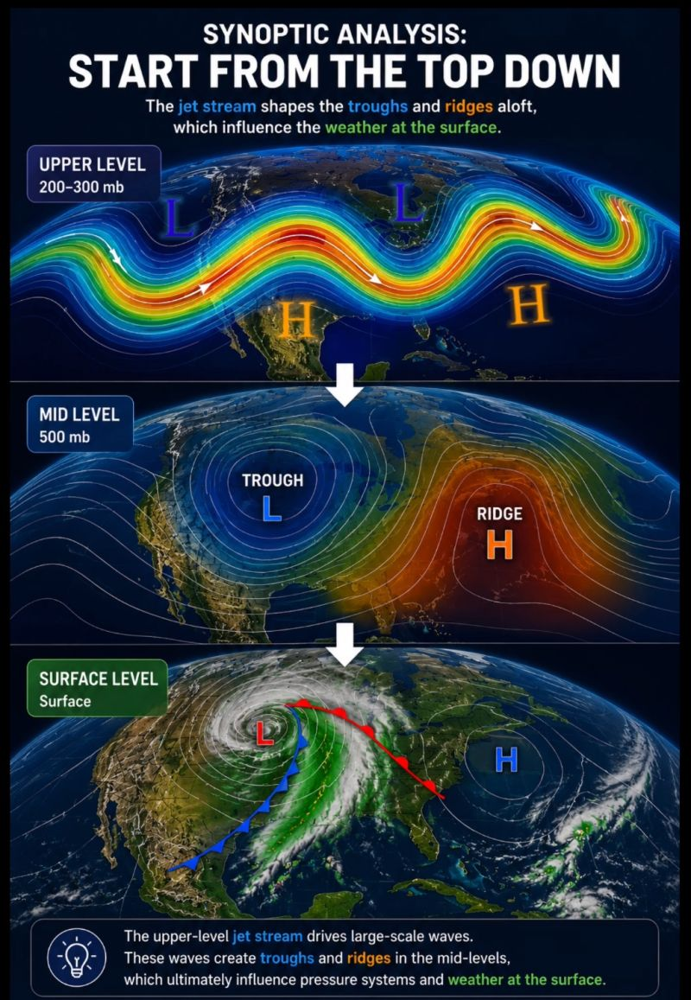

Extraído de: Abdullah Oraif (LinkedIn link: https://lnkd.in/p/ddyRmmxF)

LinkedIn de Abdullah Orailf: https://www.linkedin.com/in/abdullah-oraif-90bb7b381/

<hr size=5 color='#002883'>

# <font size=6 color='#002883'> **1. preparação do Colab** <font>

<font size=4 color='#002883'> Executar as três células de abaixo: <font>

<font size=4 color='#002883'>1.1. Montar o drive para acesso a nossa pasta de trabalho <font>

In [1]:
# @title #### <font color='#002883'> Montar o drive para a importação da livraria utilities_new_version <font>
%%capture

from google.colab import drive
drive.mount('/content/drive')

<font size=4 color='#002883'>1.2. Adicionar o caminho do sistema para a importação do utilities_new_version.py <font>

In [2]:
# @title #### <font color='#002883'> Adicionar o caminho do Drive ao caminho do sistema para importação de módulos <font>
%%capture

import sys
sys.path.append('/content/drive/MyDrive/')

<font size=4 color='#002883'>1.3. Instaçaão de livrarias <font>

In [3]:
# @title #### <font color='#002883'> Instalar livrarias <font>
%%capture

!pip install imgaug
!pip install siphon

# Instalando a Biblioteca Pygrib
!pip install pygrib
#print('\n')

# Instalando a Biblioteca Cartopy
!pip install cartopy
!pip install shapely --no-binary shapely --force
#print('\n')

# Instalando a Biblioteca MetPy
!pip install "numpy<2.0" metpy --upgrade
#!pip install MetPy
#print('\n')

# Instalando a Biblioteca Boto3
!pip install boto3
#print('\n')

# Instalando a Biblioteca NetCDF4
!pip install netcdf4
#print('\n')

# Instalando a biblioteca para trabalhar arquivos .grib com a livraria xarray
!pip install -q cfgrib eccodes

# Instalando / atualizando a Biblioteca GDAL
!apt-add-repository -y ppa:ubuntugis/ubuntugis-unstable
!add-apt-repository -y ppa:ubuntugis/ppa
!apt-get install gdal-bin
!pip install 'gdal==3.0.4'
#print('\n')

# Install ImageMagick
!sudo apt install imagemagick
#print('\n')

<font size=4 color='#002883'>1.4. Reiniciar a sessão de trabalho. Necessário para a importação do módulo de Metpy <font>

In [ ]:
# @title #### <font color='#002883'> Reiniciar sessão devido ao modulo do Metpy <font>
%%capture

import os
os.kill(os.getpid(), 9)

<font size=4 color='#002883'> **2. Fazer downloand de arquivos complementários (e.g., shapefile de estados e provincias do Brasil e outros paises). Além disso, fazer o download do arquivo utilities.py para o uso no processamento de imagens de satélite da série GOES. Download do arquivo CPT para o realce do canal infravermelho e vapor d'água.** <font>

In [1]:
# @title #### <font color='#002883'> Baixar arquivos complementários <font>
%%capture

# Baixando o shapefile dos estados brasileiros
!wget -c https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados brasileiros
!unzip -o br_unidades_da_federacao.zip
#print('\n')

# Baixando o shapefile dos estados / províncias mundiais
!wget -c https://www.naturalearthdata.com/http//www.naturalearthdata.com/download/10m/cultural/ne_10m_admin_1_states_provinces.zip
#print('\n')

# Descomprimindo o arquivo de shapefile dos estados / províncias mundiais
!unzip -o ne_10m_admin_1_states_provinces.zip
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais IR)
!wget -c https://www.dropbox.com/s/fdgnaqt91cy3x97/IR4AVHRR6.cpt
#print('\n')

# Download da arquivo CPT exemplo (para realce de canais WV)
!wget -c https://www.dropbox.com/s/4l9fys6pv5c68xk/SVGAWVX_TEMP.cpt
#print('\n')

<font size=4 color='#002883'> **3. Importar livrarias.** <font>

In [2]:
# @title #### <font color='#002883'> Importar livrarias para o processamento dos dados <font>
%%capture

from datetime import datetime
import os
import requests
import time as t
import sys

# Livrarias para leitura, processamento e plot de dados NetCDF
from netCDF4 import Dataset
from osgeo import gdal
import matplotlib.pyplot as plt
import cartopy, cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import os
import numpy as np
from matplotlib import cm
from matplotlib.colors import BoundaryNorm, ListedColormap
from datetime import timedelta, date, datetime
import pygrib
import xarray as xr
gdal.PushErrorHandler('CPLQuietErrorHandler')

# Livrarias para o cálculo de campos meteorológicos
from metpy.units import units
import metpy.calc as mpcalc
import numpy.ma as ma

# Carregar a nova versão do utilities_new_version.py
#import sys
#folder_path = '/content/drive/MyDrive/USP-CURSOS/MONITORIA/METEOROLOGIA-SINOTICA-II-2026'
#if folder_path not in sys.path:
#    sys.path.append(folder_path)
#from utilities_new_version import download_CMI
#from utilities_new_version import reproject
#from utilities_new_version import loadCPT

<font size=4 color='red'> **4.1. Função para o download dos dados do modelo Global forecasting System (GFS).** <font>

In [3]:
# @title #### <font color='#002883'> Construir função para o download dos arquivos do GFS <font>
%%capture

# Link (select "grib filter" and check "Show the URL only for web programming" to verify the URL's):
# https://nomads.ncep.noaa.gov/

def download_gfs(date, iii):

    # Create the URL's based on the resolution
    if (resolution == '25'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '50'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_0p'+resolution+'.pl?file=gfs.t'+hour_run+'z.pgrb2full.0p'+resolution+'.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.0p'+resolution+'.f'+str(hour).zfill(3)
        res = 'prgb2.0p'+resolution+'.f'
    elif (resolution == '1'):
        url = 'https://nomads.ncep.noaa.gov/cgi-bin/filter_gfs_'+resolution+'p00.pl?file=gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)+'&all_lev=on&all_var=on&subregion=&leftlon='+min_lon+'&rightlon='+max_lon+'&toplat='+max_lat+'&bottomlat='+min_lat+'&dir=%2Fgfs.'+date+'%2F'+hour_run+'%2Fatmos'
        file_name = 'gfs.t'+hour_run+'z.pgrb2.'+resolution+'p00.f'+str(hour).zfill(3)
        res = 'prgb2.'+resolution+'p00.f'

    # Print the file name
    print("File name: ", file_name)
    # Sends a GET request to the specified url
    myfile = requests.get(url)

    # Download the file
    open(dir + '//' + file_name, 'wb').write(myfile.content)

<font size=4 color='red'> **4.2. Função para o download de dados do Geostationary Operational Environmental Satellite - 19 (GOES-19) do Amazon Web Services (AWS).** <font>

In [4]:
# @title #### <font color='#002883'> Construir função para o download dos arquivos do GOES-19 <font>
%%capture

# ==========================================================================================================
# Training: Python and GOES-19 Imagery: Functions for download data from AWS
# ==========================================================================================================
# Required modules
import os                                # Miscellaneous operating system interfaces
import numpy as np                       # Import the Numpy package
import colorsys                          # To make convertion of colormaps
import boto3                             # Amazon Web Services (AWS) SDK for Python
from botocore import UNSIGNED            # boto3 config
from botocore.config import Config       # boto3 config
import math                              # Mathematical functions
from datetime import datetime            # Basic Dates and time types
from osgeo import osr                    # Python bindings for GDAL
from osgeo import gdal                   # Python bindings for GDAL

#from netCDF4 import Dataset          # Read / Write NetCDF4 files
#import matplotlib.pyplot as plt      # Plotting library
#import cartopy, cartopy.crs as ccrs  # Plot maps
##import sys
#from datetime import timedelta, date, datetime   # Manipulate dates

# ==========================================================================================================
def loadCPT(path):

    try:
        f = open(path)
    except:
        print ("File ", path, "not found")
        return None

    lines = f.readlines()

    f.close()

    x = np.array([])
    r = np.array([])
    g = np.array([])
    b = np.array([])

    colorModel = 'RGB'

    for l in lines:
        ls = l.split()
        if l[0] == '#':
            if ls[-1] == 'HSV':
                colorModel = 'HSV'
                continue
            else:
                continue
        if ls[0] == 'B' or ls[0] == 'F' or ls[0] == 'N':
            pass
        else:
            x=np.append(x,float(ls[0]))
            r=np.append(r,float(ls[1]))
            g=np.append(g,float(ls[2]))
            b=np.append(b,float(ls[3]))
            xtemp = float(ls[4])
            rtemp = float(ls[5])
            gtemp = float(ls[6])
            btemp = float(ls[7])

        x=np.append(x,xtemp)
        r=np.append(r,rtemp)
        g=np.append(g,gtemp)
        b=np.append(b,btemp)

    if colorModel == 'HSV':
        for i in range(r.shape[0]):
            rr, gg, bb = colorsys.hsv_to_rgb(r[i]/360.,g[i],b[i])
        r[i] = rr ; g[i] = gg ; b[i] = bb

    if colorModel == 'RGB':
        r = r/255.0
        g = g/255.0
        b = b/255.0

    xNorm = (x - x[0])/(x[-1] - x[0])

    red   = []
    blue  = []
    green = []

    for i in range(len(x)):
        red.append([xNorm[i],r[i],r[i]])
        green.append([xNorm[i],g[i],g[i]])
        blue.append([xNorm[i],b[i],b[i]])

    colorDict = {'red': red, 'green': green, 'blue': blue}

    return colorDict

# ==========================================================================================================

def download_CMI(yyyymmddhhmn, band, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"
    product_name = "ABI-L2-CMIPF"

    # Initializes the S3 client
    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6C{int(band):02.0f}_G19_s{year}{day_of_year}{hour}{min}"

    # Search for the file on the server
    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Band-{band}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_PROD(yyyymmddhhmn, product_name, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%H")
    min = datetime.strptime(yyyymmddhhmn, "%Y%m%d%H%M").strftime("%M")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}-M6_G19_s{year}{day_of_year}{hour}{min}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmn}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
def download_GLM(yyyymmddhhmnss, path_dest):

    os.makedirs(path_dest, exist_ok=True)

    year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%Y")
    day_of_year = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%j")
    hour = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%H")
    min = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%M")
    seg = datetime.strptime(yyyymmddhhmnss, "%Y%m%d%H%M%S").strftime("%S")

    # AMAZON repository information (MUDADO PARA GOES-19)
    bucket_name = "noaa-goes19"

    s3_client = boto3.client("s3", config=Config(signature_version=UNSIGNED))

    product_name = "GLM-L2-LCFA"
    # File structure (MUDADO PARA _G19_)
    prefix = f"{product_name}/{year}/{day_of_year}/{hour}/OR_{product_name}_G19_s{year}{day_of_year}{hour}{min}{seg}"

    s3_result = s3_client.list_objects_v2(
        Bucket=bucket_name, Prefix=prefix, Delimiter="/"
    )

    if "Contents" not in s3_result:
        print(f"No files found for the date: {yyyymmddhhmnss}, Product-{product_name}")
        return -1
    else:
        for obj in s3_result["Contents"]:
            key = obj["Key"]
            file_name = key.split("/")[-1].split(".")[0]

            if os.path.exists(f"{path_dest}/{file_name}.nc"):
                print(f"File {path_dest}/{file_name}.nc exists")
            else:
                print(f"Downloading file {path_dest}/{file_name}.nc")
                s3_client.download_file(
                    bucket_name, key, f"{path_dest}/{file_name}.nc"
                )
    return f"{file_name}"

# ==========================================================================================================
# Function to convert lat / lon extent to GOES-19 extents
def convertExtent2GOESProjection(extent):
    GOES19_HEIGHT = 35786023.0
    # Longitude de sub-satélite do GOES-19 (GOES-East operacional)
    GOES19_LONGITUDE = -75.2

    a, b = latlon2xy(extent[1], extent[0])
    c, d = latlon2xy(extent[3], extent[2])
    return (a * GOES19_HEIGHT, c * GOES19_HEIGHT, b * GOES19_HEIGHT, d * GOES19_HEIGHT)

# ==========================================================================================================
# Functions to convert lat / lon extent to array indices
def geo2grid(lat, lon, nc):

    # Apply scale and offset
    xscale, xoffset = nc.variables['x'].scale_factor, nc.variables['x'].add_offset
    yscale, yoffset = nc.variables['y'].scale_factor, nc.variables['y'].add_offset

    x, y = latlon2xy(lat, lon)
    col = (x - xoffset)/xscale
    lin = (y - yoffset)/yscale
    return int(lin), int(col)

# ==========================================================================================================
def latlon2xy(lat, lon):
    # goes_imagery_projection:semi_major_axis
    req = 6378137 # meters
    #  goes_imagery_projection:inverse_flattening
    invf = 298.257222096
    # goes_imagery_projection:semi_minor_axis
    rpol = 6356752.31414 # meters
    e = 0.0818191910435
    # goes_imagery_projection:perspective_point_height + goes_imagery_projection:semi_major_axis
    H = 42164160 # meters
    # goes_imagery_projection: longitude_of_projection_origin
    lambda0 = -1.308996939

    # Convert to radians
    latRad = lat * (math.pi/180)
    lonRad = lon * (math.pi/180)

    # (1) geocentric latitude
    Phi_c = math.atan(((rpol * rpol)/(req * req)) * math.tan(latRad))
    # (2) geocentric distance to the point on the ellipsoid
    rc = rpol/(math.sqrt(1 - ((e * e) * (math.cos(Phi_c) * math.cos(Phi_c)))))
    # (3) sx
    sx = H - (rc * math.cos(Phi_c) * math.cos(lonRad - lambda0))
    # (4) sy
    sy = -rc * math.cos(Phi_c) * math.sin(lonRad - lambda0)
    # (5)
    sz = rc * math.sin(Phi_c)

    # x,y
    x = math.asin((-sy)/math.sqrt((sx*sx) + (sy*sy) + (sz*sz)))
    y = math.atan(sz/sx)

    return x, y

# ==========================================================================================================
# Function to reproject the data
def reproject(file_name, ncfile, array, extent, undef):

    # Read the original file projection and configure the output projection
    source_prj = osr.SpatialReference()
    source_prj.ImportFromProj4(ncfile.GetProjectionRef())

    target_prj = osr.SpatialReference()
    target_prj.ImportFromProj4("+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs")

    # Reproject the data
    GeoT = ncfile.GetGeoTransform()
    driver = gdal.GetDriverByName('MEM')
    raw = driver.Create('raw', array.shape[0], array.shape[1], 1, gdal.GDT_Float32)
    raw.SetGeoTransform(GeoT)
    raw.GetRasterBand(1).WriteArray(array)

    # Define the parameters of the output file
    kwargs = {'format': 'netCDF', \
            'srcSRS': source_prj, \
            'dstSRS': target_prj, \
            'outputBounds': (extent[0], extent[3], extent[2], extent[1]), \
            'outputBoundsSRS': target_prj, \
            'outputType': gdal.GDT_Float32, \
            'srcNodata': undef, \
            'dstNodata': 'nan', \
            'resampleAlg': gdal.GRA_NearestNeighbour}

    # Write the reprojected file on disk
    gdal.Warp(file_name, raw, **kwargs)


<font size=4 color='#002883'> **5. Download dos dados do modelo Global forecasting System (GFS). É necessário editar a data Year = YYYY, month = mm, day = dd e hour = hh. Os dados do GFS só estão disponíveis até 5 dias atrás da data atual.** <font>

In [5]:
# @title #### <font color='#002883'> Download dos dados do GFS <font>
#%%capture

# Configurar a data de acesso aos dados do GFS
year = 2026
month = 9
day = 14
hour = 00

# Extensão desejada - COLOCAR AQUI ENTRE ASPAS POIS É UMA STRING
# longitude de -180 a 180
min_lon = '-122.50'
max_lon = '12.50'
min_lat = '-80.0'
max_lat = '25.0'

print('---------------------------------------')
print('GFS Download (NOMADS) - Script started.')
print('---------------------------------------')

# Start the time counter
start_time = t.time()

# Data desejada (Únicamente os últimos 10 dias!): Formato - 'YYYY, MM, DD, HH'
dt = datetime(year, month, day, hour)
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite

#-----------------------------------------------------------------------------------------------------------

# Download diretório
dir = "Samples"; os.makedirs(dir, exist_ok=True)

# Data desajada (Únicamente os últimos 10 dias!): Formato - 'YYYYMMDD'
date = (f'{dt:%Y%m%d}')

# Resolução espacial desejada: '25' or '50' or '1'
resolution = '25' #'1'

# Hora de execução: '00' or '06' or '12' or '18'
#hour_run = '00'
hour_run=(f'{dt:%H}')

# Horas de previsão
hour_ini = 0  # Init time
hour_end = 0 # End time
hour_int = 3  # Interval

if (resolution == '25'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '50'):
  res = 'pgrb2.0p'+resolution+'.f'
elif (resolution == '1'):
  res = 'pgrb2.'+resolution+'p00.f'

#-----------------------------------------------------------------------------------------------------------

# Download loop
for hour in range(hour_ini, hour_end + 1, hour_int):
    print('\n---------------------')
    print('Downloading GFS File:')
    print('---------------------')
    print('Resolution: ' + resolution)
    print('Date: ' + date)
    print('Run: ' + hour_run)
    print('Forecast Hour: f' + str(hour).zfill(3))
    # Call the download function
    download_gfs(date,hour)

# End the time counter
print('\nTotal Processing Time:', round((t.time() - start_time),2), 'seconds.')

---------------------------------------
GFS Download (NOMADS) - Script started.
---------------------------------------

---------------------
---------------------
Resolution: 25
Date: 20260914
Run: 00
Forecast Hour: f000
File name:  gfs.t00z.pgrb2.0p25.f000

Total Processing Time: 18.57 seconds.


<font size=4 color='#002883'> **6. Download dos dados de satélite do GOES-19.** <font>

In [6]:
# @title #### <font color='#002883'> Download de GOES-19 <font>
#%%capture

# Seleção da extensão [min. lon, min. lat, max. lon, max. lat]
# Lembrar que longitude está definida entre -180 e 180
extent = [float(min_lon), float(min_lat), float(max_lon), float(max_lat)]

# Input e output directorios
input = "/content/Samples"; os.makedirs(input, exist_ok=True)
output = "/content/Output"; os.makedirs(output, exist_ok=True)

#-----------------------------------------------------------------------------------------------------------
date = (f'{dt:%Y%m%d}')
yyyymmddhhmn = (f'{dt:%Y%m%d%H}00') # Data e hora da imagem de satélite
hour_run=(f'{dt:%H}')

# Download the ABI file channel 13 - Clean IR
file_ir = download_CMI(yyyymmddhhmn, 13, input)

# Variable
var = 'CMI'
# Abrir o dado
img = gdal.Open(f'NETCDF:{input}/{file_ir}.nc:' + var)

# Ler os metadados
metadata = img.GetMetadata()
scale = float(metadata.get(var + '#scale_factor'))
offset = float(metadata.get(var + '#add_offset'))
undef = float(metadata.get(var + '#_FillValue'))
dtime = metadata.get('NC_GLOBAL#time_coverage_start')

# Carregar os dados
ds_cmi = img.ReadAsArray(0, 0, img.RasterXSize, img.RasterYSize).astype(float)

# Aplicar a escala, offset e converter de Kelvin para Graus Celcius
ds_cmi = (ds_cmi * scale + offset) - 273.15

# Reprojeção do arquivo
filename_ret = f'{output}/IR_{yyyymmddhhmn}.nc'
reproject(filename_ret, img, ds_cmi, extent, undef)

# Ler a imagem do GOES-19 reprojetada
file = Dataset(filename_ret)

# Acessar aos valores dos pixel
data = file.variables['Band1'][:]

/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


<font size=4 color='#002883'> **7. Definir os campos meteorológicos por níveis do GFS.** <font>

In [7]:
# @title #### <font color='#002883'> Definir as variáveis do GFS por níveis <font>
%%capture

# Ler o dado grib do GFS
grib = pygrib.open(f'Samples/gfs.t{hour_run}z.{res}000')

# Selecionar a variável
mslp = grib.select(name='Pressure reduced to MSL')[0]

# Acessar informação do arquivo
init  = str(mslp.analDate)      # Init date / time
run   = str(mslp.hour).zfill(2) # Run
ftime = str(mslp.forecastTime)  # Forecast hour
valid = str(mslp.validDate)     # Valid date / time
print('Init: ' + init + ' UTC')
print('Run: ' + run + 'Z')
print('Forecast: +' + ftime)
print('Valid: ' + valid + ' UTC')

# ========================================================================
# VARIÁVEIS DE SUPERFÍCIE:
# - Pressão reduzida ao nível medio do mar
# - Taxa de precipitação
#
# VARIÁVEL DE TODA A COLUNA ATMOSFÉRICA:
# - Água precipitável
# ========================================================================
# Ler a data da região específica
# Longitude tem que estar entre 0 e 360 graus
mslp, lats, lons = mslp.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Converter para hPa
mslp = mslp / 100

# Selecionar a variável
prtwt = grib.select(name='Precipitable water')[0]
prtwt = prtwt.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Quero somente valores maiores que 40
mask_prtwt = ma.masked_less(prtwt, 40).mask
prtwt[mask_prtwt] = np.nan

# Busca a variável de taxa de precipitação na superfície
precip_rate = grib.select(name='Precipitation rate', typeOfLevel='surface')[0]

# ========================================================================
# ALTURA GEOPOTENCIAL
# ========================================================================
# Select the variable
hght_1000 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
hght_1000 = hght_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_850 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
hght_850 = hght_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_700 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Read the data for a specific region
hght_700 = hght_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_500 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
hght_500 = hght_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
hght_250 = grib.select(name='Geopotential height', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Read the data for a specific region
hght_250 = hght_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# ESPESSURA
# ========================================================================
# Calculate and smooth 1000-500 hPa thickness
thickness_1000_500 = hght_500 - hght_1000
# Calculate and smooth 1000-850 hPa thickness
thickness_1000_850 = hght_850 - hght_1000

# ========================================================================
# COMPONENTES ZONAL (U) E MERIDIONAL (V) DO VENTO
# ========================================================================
# Select the variable
u_1000 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
u_1000, lats, lons = u_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_1000 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 1000)[0]
# Read the data for a specific region
v_1000 = v_1000.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
u_925 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
u_925, lats, lons = u_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_925 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 925)[0]
# Ler a data para a região específica
v_925 = v_925.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
u_850 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
u_850, lats, lons = u_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_850 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Read the data for a specific region
v_850 = v_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
u_500 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
u_500, lats, lons = u_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Select the variable
v_500 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Read the data for a specific region
v_500 = v_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
u_250 = grib.select(name='U component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
u_250, lats, lons = u_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])
# Selecionar a variável
v_250 = grib.select(name='V component of wind', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Ler a data para a região específica
v_250 = v_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# OMEGA
# ========================================================================
# Selecionar a variável
w_850 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
w_850 = w_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
w_500 = grib.select(name='Vertical velocity', typeOfLevel = 'isobaricInhPa', level = 500)[0]
# Ler a data para a região específica
w_500 = w_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# UMIDADE ESPECÍFICA
# ========================================================================
# Selecionar a variável
spch_850 = grib.select(name='Specific humidity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler os dados da região de estudo
spch_850 = spch_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# TEMPERATURA DO AR
# ========================================================================
# Selecionar a variável
temp_850 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
temp_850 = temp_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Selecionar a variável
temp_500 = grib.select(name='Temperature', typeOfLevel='isobaricInhPa', level=500)[0]
# Ler a data para a região específica
temp_500 = temp_500.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# Select the variable
temp_250 = grib.select(name='Temperature', typeOfLevel = 'isobaricInhPa', level = 250)[0]
# Read the data for a specific region
temp_250 = temp_250.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# ========================================================================
# UMIDADE RELATIVA
# ========================================================================
# Selecionar a variável
relhum_800 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 800)[0]
# Ler a data para a região específica
relhum_800 = relhum_800.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_850 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 850)[0]
# Ler a data para a região específica
relhum_850 = relhum_850.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]
# Selecionar a variável
relhum_700 = grib.select(name='Relative humidity', typeOfLevel = 'isobaricInhPa', level = 700)[0]
# Ler a data para a região específica
relhum_700 = relhum_700.data(lat1=extent[1],lat2=extent[3],lon1=extent[0],lon2=extent[2])[0]

# calculando umidade relativa média entre 800 e 700 hPa
relhum = (relhum_800 + relhum_850 + relhum_700)/3

# Calculando com metpy
dx, dy = mpcalc.lat_lon_grid_deltas(lons, lats)

# ========================================================================
# NIVEL = 1000 hPa
# ========================================================================
u_1000 = units('m/s') * u_1000
v_1000 = units('m/s') * v_1000

# ========================================================================
# NIVEL = 925 hPa
# ========================================================================
# Calculando divergencia em 925 hPa
nivel_925 = 925
pressure = units('Pa') * nivel_925 * 100
u_925 = units('m/s') * u_925
v_925 = units('m/s') * v_925
# Calcular divergência
div_925 = mpcalc.divergence(u_925, v_925, dx=dx, dy=dy)
# Mascara para só obter a convergencia
mask_conv = ma.masked_greater_equal(div_925, 0).mask
div_925[mask_conv] = np.nan

# ========================================================================
# NIVEL = 850 hPa
# ========================================================================
nivel_850 = 850
pressure_850 = units('Pa') * nivel_850 * 100
u_850 = units('m/s') * u_850
v_850 = units('m/s') * v_850
temp_850 = units('K') * temp_850
# Cálculo das componentes do Q-vetor
uqvect, vqvect = mpcalc.q_vector(u=u_850, v=v_850, temperature=temp_850, pressure=pressure_850, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores calculado anteriormente
q_div = 2*mpcalc.divergence(uqvect, vqvect, dx=dx, dy=dy)
# Cálculo da temperatura potencial para o cálculo da frontogenesis
theta = mpcalc.potential_temperature(pressure = pressure_850, temperature = temp_850)
# Cálculo da temperatura do ponto de orvalho
dewp = mpcalc.dewpoint_from_specific_humidity(pressure = pressure_850, temperature = temp_850, specific_humidity = spch_850)
# Cálculo da tempeatura potencial equivalente
thetae = mpcalc.equivalent_potential_temperature(pressure = pressure_850, temperature = temp_850, dewpoint = dewp)
# Cálculo da frontogenesis
fronto = mpcalc.frontogenesis(potential_temperature = theta, u = u_850, v = v_850, dx = dx, dy = dy)
# Fator de conversão das unidades da frontogenesis K por 100 km por 3 h
convert_to_per_100km_3h = 1000*100*3600*3
# Calculando a vorticidade em 850 hPa
zeta_850 = mpcalc.vorticity(u_850,v_850, dx = dx, dy = dy)
# Quero somente os valores menores que 0
mask_zeta = ma.masked_greater_equal(zeta_850, 0).mask
zeta_850[mask_zeta] = np.nan
# Cálculo da advecção de temperatura
#T = temp_850
adv = mpcalc.advection(temp_850, u = u_850, v = v_850, dx = dx, dy = dy)

# Quero somente os valores negativos de omega
mask_omega = ma.masked_greater_equal(w_850, 0).mask
w_850[mask_omega] = np.nan

# ========================================================================
# NIVEL = 500 hPa
# ========================================================================
nivel_500 = 500
pressure_500 = units('Pa') * nivel_500 * 100
u_500 = units('m/s') * u_500
v_500 = units('m/s') * v_500
temp_500 = units('K') * temp_500
# Cálculo das componentes do Q-vetor
uqvect_500, vqvect_500 = mpcalc.q_vector(u = u_500, v = v_500, temperature=temp_500, pressure=pressure_500, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores
q_div_500 = 2*mpcalc.divergence(uqvect_500, vqvect_500, dx=dx, dy=dy)
# Cálculo da vorticidade
zeta_500 = mpcalc.vorticity(u_500,v_500, dx = dx, dy = dy)
#Quero somente os valores menores que 0
#mask_zeta = ma.masked_greater_equal(zeta_500, 0).mask
#zeta_500[mask_zeta] = np.nan
# Cálculo da advecção da vorticidade
#T = zeta_500
adv_zeta = mpcalc.advection(zeta_500, u = u_500, v = v_500, dx = dx, dy = dy)

# Só valores negativos de omega
mask_omega = ma.masked_greater_equal(w_500, 0).mask
w_500[mask_omega] = np.nan

# ========================================================================
# NIVEL = 250 hPa
# ========================================================================
# Calculando divergencia em 250 hPa
nivel_250 = 250
pressure_250 = units('Pa') * nivel_250 * 100
u_250 = units('m/s') * u_250
v_250 = units('m/s') * v_250
temp_250 = units('K') * temp_250

# Use MetPy to calculate the wind speed for colorfill plot, change units to knots from m/s
speed_jet = mpcalc.wind_speed(u_250, v_250)
#Quero somente os valores maiores que 30 m/s
mask_jet = ma.masked_less_equal(speed_jet, 30).mask
speed_jet[mask_jet] = np.nan

# Cálculo da divergência
div_250 = mpcalc.divergence(u_250, v_250, dx=dx, dy=dy)
# Só valores de convergência
mask_div = ma.masked_less_equal(div_250, 0).mask
div_250[mask_div] = np.nan

# Cálculo das componentes do Q-vetor
uqvect_250, vqvect_250 = mpcalc.q_vector(u = u_250, v = v_250, temperature=temp_250, pressure=pressure_250, dx=dx, dy=dy)
# Cálculo da divergência dos Q-vetores
q_div_250 = 2*mpcalc.divergence(uqvect_250, vqvect_250, dx=dx, dy=dy)


<font size=4 color='red'> **Observação: Para listar as variáveis disponíveis pelo modelo GFS, rodar a seguinte célular.** <font>

In [8]:
# @title #### <font color='red'> Listar variáveis do modelo GFS <font>
%%capture

for grb in grib:
    print(grb)  # Imprime diretamente: número, nome, unidades, tipo de nível e valor do nível

grib.close()

<font size=4 color='#002883'> **8. Converter a Analysis do modelo GFS do formato .grib2 para o formato .nc (NetCDF). Com os dados no formato NetCDF é possível fazer os corter verticais para identificação do Jato Subtropical (JST) e do Jato Polar (JP)** <font>


<font size=4 color='red'> **Observação: Só as variáveis com níveis de pressão ("typeOfLevel": "isobaricInhPa") que serão transformadas do formato .grib2 para o formato .nc** <font>

In [9]:
# @title #### <font color='#002883'> Transformar do formato .grib2 para .nc (Só as variáveis com níveis de pressão que serão transformadas) <font>
#%%capture

import logging

# Silencia os logs do cfgrib
logging.getLogger("cfgrib").setLevel(logging.CRITICAL)

ds = xr.open_dataset(
    f'Samples/gfs.t{hour_run}z.{res}000',
    engine="cfgrib",
    backend_kwargs={
        "filter_by_keys": {
            "typeOfLevel": "isobaricInhPa"
        },
        "indexpath": ""
    }
)

ds

<xarray.Dataset> Size: 301MB
Dimensions:        (isobaricInhPa: 33, latitude: 421, longitude: 541)
Coordinates:
  * isobaricInhPa  (isobaricInhPa) float64 264B 1e+03 975.0 950.0 ... 2.0 1.0
  * latitude       (latitude) float64 3kB -80.0 -79.75 -79.5 ... 24.5 24.75 25.0
  * longitude      (longitude) float64 4kB -122.5 -122.2 -122.0 ... 12.25 12.5
    time           datetime64[ns] 8B ...
    step           timedelta64[ns] 8B ...
    valid_time     datetime64[ns] 8B ...
Data variables:
    gh             (isobaricInhPa, latitude, longitude) float32 30MB ...
    t              (isobaricInhPa, latitude, longitude) float32 30MB ...
    r              (isobaricInhPa, latitude, longitude) float32 30MB ...
    q              (isobaricInhPa, latitude, longitude) float32 30MB ...
    w              (isobaricInhPa, latitude, longitude) float32 30MB ...
    wz             (isobaricInhPa, latitude, longitude) float32 30MB ...
    u              (isobaricInhPa, latitude, longitude) float32 30MB ...
    v              (isobaricInhPa, latitude, longitude) float32 30MB ...
    absv           (isobaricInhPa, latitude, longitude) float32 30MB ...
    o3mr           (isobaricInhPa, latitude, longitude) float32 30MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             kwbc
    GRIB_centreDescription:  US National Weather Service - NCEP
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             US National Weather Service - NCEP
    history:                 2026-09-14T17:25 GRIB to CDM+CF via cfgrib-0.9.1...

<font size=4 color='#002883'> **9. Calculando a velocidade do vento considerando só as componentes zonal (u) e meridional (v). Além disso, calculando a Temperatura Potencialo fazendo uso da livraria Metpy** <font>

In [10]:
# @title #### <font color='#002883'> Cálculo da magnitude da velocidade do vento e da Temperatura Potencial <font>
%%capture

# MAGNITUDE DO VENTO
ds['wind_speed'] = mpcalc.wind_speed(ds['u'], ds['v'])  #np.sqrt(ds['u']**2 + ds['v']**2)

# TEMPERATURA POTENCIAL
ds['theta'] = mpcalc.potential_temperature(ds['isobaricInhPa'], ds['t'])
ds

<font size=4 color='#002883'> **10. Plot da imagem de satélite + PRNMM + Espessura 1000-500 hPa + Vento (barbelas, knots) 1000 hPa** <font>

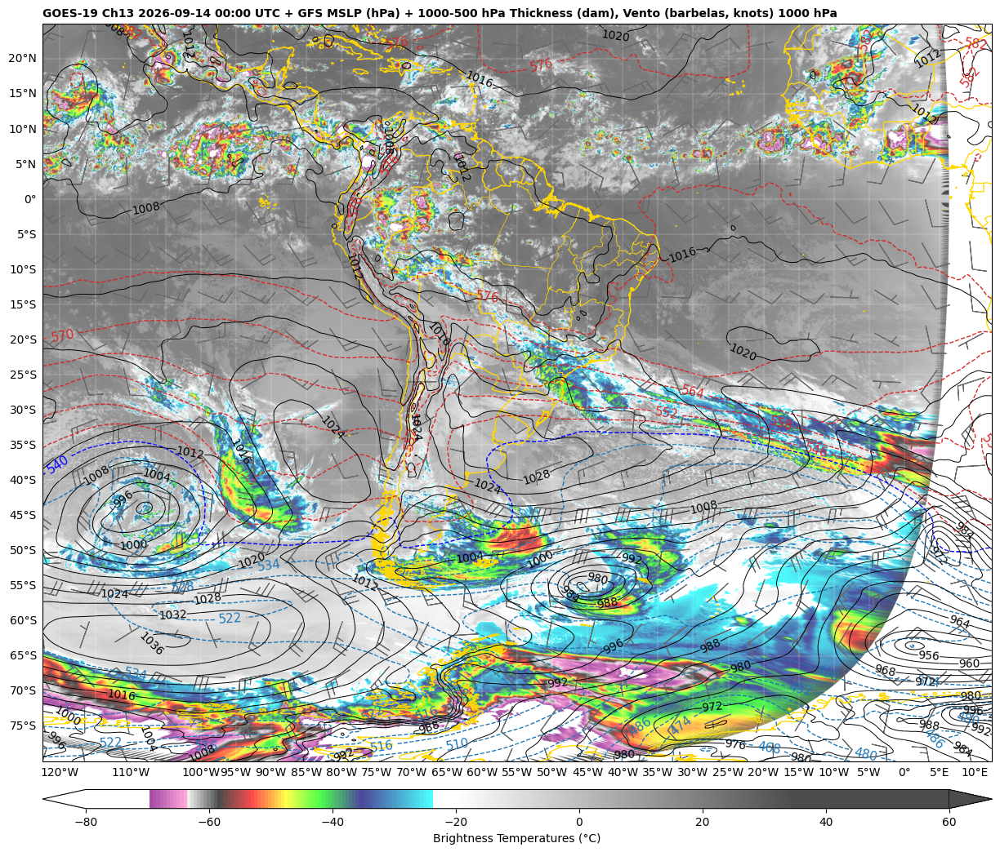

In [13]:
# @title #### <font color='#002883'> Imagem de satélite + PRNMM + Espessura 1000-500 hPa + vento (barbelas) 1000 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# Define the color scale based on the channel
# Converts a CPT file to be used in Python
cpt = loadCPT('IR4AVHRR6.cpt')
colormap = cm.colors.LinearSegmentedColormap('cpt', cpt)

# Plot the image
img1 = ax.imshow(
    data,
    origin='upper',
    vmin=-80,
    vmax=60,
    extent=img_extent,
    cmap=colormap,
    alpha=0.7
)

# Add a colorbar
plt.colorbar(
    img1,
    label='Brightness Temperatures (°C)',
    extend='both',
    orientation='horizontal',
    pad=0.03,
    aspect = 50
)

# Plot thickness with multiple colors
clevs = (np.arange(0, 540, 6),
         np.array([540]),
         np.arange(546, 700, 6))
colors = ('tab:blue', 'b', 'tab:red')
kw_clabels = {'fontsize': 11, 'inline': True, 'inline_spacing': 5, 'fmt': '%i',
              'rightside_up': True, 'use_clabeltext': True}
# suavizado da espessura
thickness_1000_500_plot = mpcalc.smooth_gaussian(thickness_1000_500, 8)

for clevthick, color in zip(clevs, colors):
    img2 = ax.contour(
        lons,
        lats,
        thickness_1000_500_plot/10,
        levels=clevthick,
        colors=color,
        linewidths=1.0,
        linestyles='dashed',
        transform=ccrs.PlateCarree()
    )
    plt.clabel(img2, **kw_clabels)

# Define de contour interval
data_min = 900
data_max = 1050
interval = 4
levels = np.arange(data_min,data_max,interval)

# Plot the contours
# Suavizando a curva de mslp
mslp_plot = mpcalc.smooth_gaussian(mslp, 8)
# plot do mslp suavizado
img3 = ax.contour(
    lons,
    lats,
    mslp_plot,
    colors='black',
    linewidths=0.7,
    levels=levels
)

# Etiquetas dos valores de pressão
ax.clabel(
    img3,
    inline=1,
    inline_spacing=0,
    fontsize='10',
    fmt = '%1.0f',
    colors= 'black'
)

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
u_1000_barb = u_1000.to(units.knot)
v_1000_barb = v_1000.to(units.knot)
flip_flag = np.zeros((u_1000_barb.shape[0],u_1000_barb.shape[1]))

# All flags below the equator will be flipped
flip_flag[lats < 0] = 1

# Plot the barbs
skip=24
bcolor='dimgrey'
# Suavizando os ventos
u_1000_barb_plot = mpcalc.smooth_gaussian(u_1000_barb, 8)
v_1000_barb_plot = mpcalc.smooth_gaussian(v_1000_barb, 8)
# Fazendo o plot
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_1000_barb_plot[::skip,::skip],
    v_1000_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip]
)
# ===========================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='gold',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='gold', linewidth=0.95)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='gold', linewidth=0.95)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='white',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 5),
    ylocs=np.arange(-90, 90, 5),
    draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(
    'GOES-19 Ch13 ' + date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' + GFS MSLP (hPa) + 1000-500 hPa Thickness (dam), Vento (barbelas, knots) 1000 hPa',
    fontweight='bold',
    fontsize=10,
    loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/Sat_mslp_Esp_V.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()

<font size=4 color='#002883'> **11. Plot de imagem de satélite + PRNMM + Espessura 1000-500 hPa + Vento em linhas de corrente (m/s) e barbelas (knots) 1000 hPa** <font>


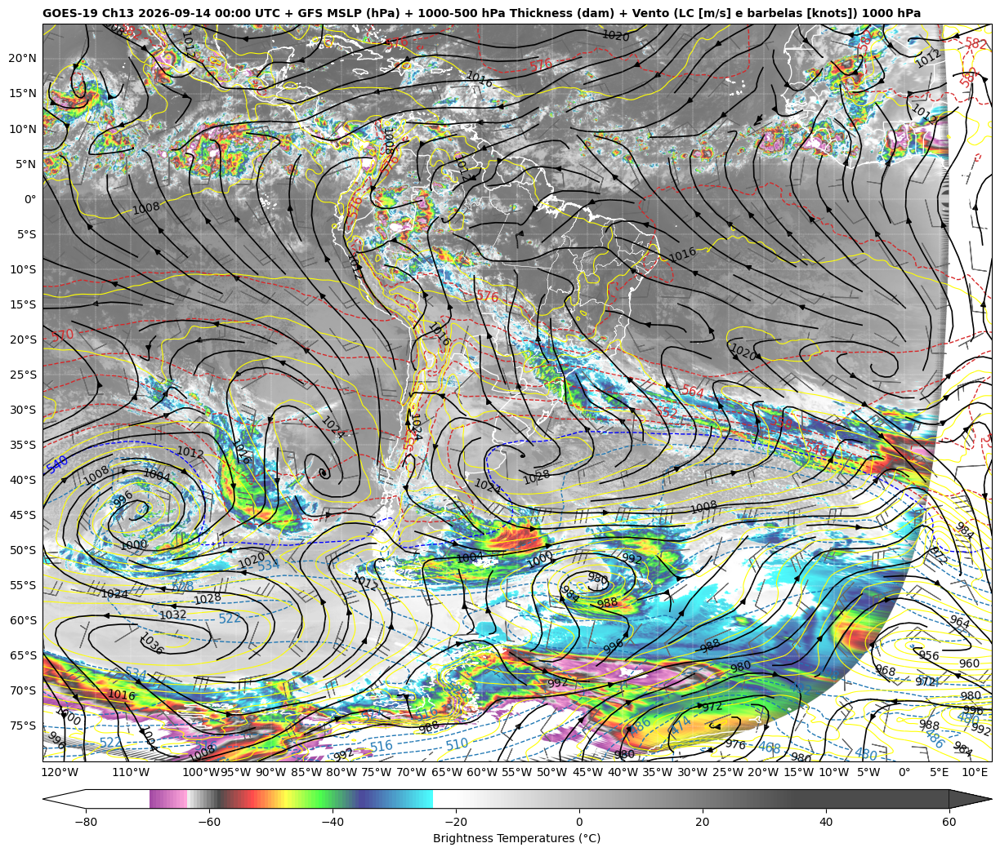

In [14]:
# @title #### <font color='#002883'> Imagem de satélite + PRNMM + Espessura 1000-500 hPa + vento (LC e barbelas) 1000 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# Define the color scale based on the channel
# Converts a CPT file to be used in Python
cpt = loadCPT('IR4AVHRR6.cpt')
colormap = cm.colors.LinearSegmentedColormap('cpt', cpt)

# Plot the image
img1 = ax.imshow(
    data,
    origin='upper',
    vmin=-80,
    vmax=60,
    extent=img_extent,
    cmap=colormap,
    alpha=0.7
)

# Add a colorbar
plt.colorbar(
    img1,
    label='Brightness Temperatures (°C)',
    extend='both',
    orientation='horizontal',
    pad=0.03,
    aspect = 50
)

# Plot thickness with multiple colors
clevs = (np.arange(0, 540, 6),
         np.array([540]),
         np.arange(546, 700, 6))
colors = ('tab:blue', 'b', 'tab:red')
kw_clabels = {'fontsize': 11, 'inline': True, 'inline_spacing': 5, 'fmt': '%i',
              'rightside_up': True, 'use_clabeltext': True}
for clevthick, color in zip(clevs, colors):
    img2 = ax.contour(
        lons,
        lats,
        thickness_1000_500_plot/10,
        levels=clevthick,
        colors=color,
        linewidths=1.0,
        linestyles='dashed',
        transform=ccrs.PlateCarree()
    )
    plt.clabel(img2, **kw_clabels)

# Define de contour interval
data_min = 900
data_max = 1050
interval = 4
levels = np.arange(data_min,data_max,interval)

# Plot the contours
img3 = ax.contour(
    lons,
    lats,
    mslp_plot,
    colors='yellow',
    linewidths=0.8,
    levels=levels
)

# Etiquetas da mslp
ax.clabel(
    img3,
    inline=1,
    inline_spacing=0,
    fontsize='10',
    fmt = '%1.0f',
    colors= 'black'
)

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_1000_barb.shape[0],u_1000_barb.shape[1]))
# All flags below the equator will be flipped
flip_flag[lats < 0] = 1
# Espaçamento das barbelas
skip=24
bcolor='dimgrey'
# Suavizando os ventos em barbelas
u_1000_barb_plot = mpcalc.smooth_gaussian(u_1000_barb, 8)
v_1000_barb_plot = mpcalc.smooth_gaussian(v_1000_barb, 8)
# Plot do vento em barbelas
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_1000_barb_plot[::skip,::skip],
    v_1000_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip]
)

# ======================================================================

# Suavizando os ventos para as LC
u_1000_plot = mpcalc.smooth_gaussian(u_1000, 8)
v_1000_plot = mpcalc.smooth_gaussian(v_1000, 8)
# Linhas de corrente
ax.streamplot(
    lons,
    lats,
    u_1000_plot,
    v_1000_plot,
    density=[1.5, 1.5],
    linewidth=1.2,
    color='black')

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='white',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='white', linewidth=0.95)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white', linewidth=0.95)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='white',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 5),
    ylocs=np.arange(-90, 90, 5),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title('GOES-19 Ch13 ' + date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' + GFS MSLP (hPa) + 1000-500 hPa Thickness (dam) + Vento (LC [m/s] e barbelas [knots]) 1000 hPa',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/Sat_mslp_Esp_V_LC.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()

<font size=4 color='#002883'> **12. Plot de Altura geopotencial [850 hPa] + Temperatura potencial equivalente [850 hPa] + Espessura 1000-850 hPa + vento [850 hPa, barbelas em knots]** <font>


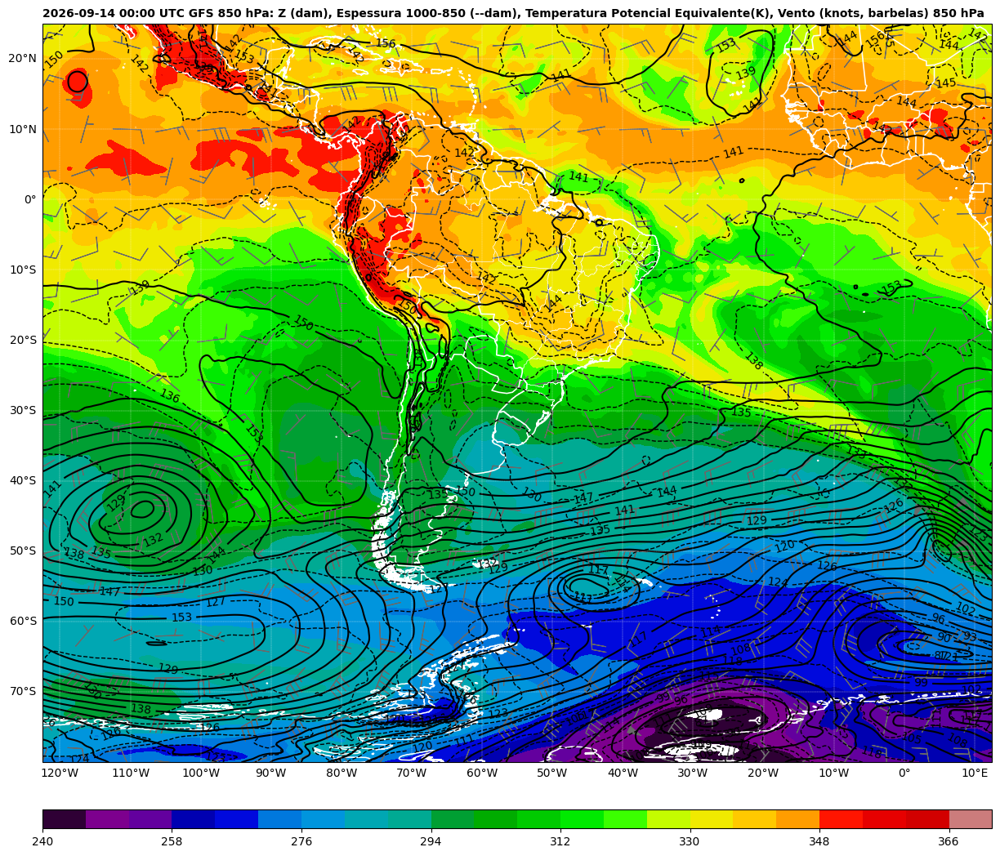

In [16]:
# @title #### <font color='#002883'> Altura gepotencial 850 hPa, Temperatura potencial equivalente 850 hPa, espessura 1000-850 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# 850-hPa thetae
clevte = np.arange(240, 377, 6)
cmap='nipy_spectral'
# Suavizando a variável
thetae_plot = mpcalc.smooth_gaussian(thetae, 8)
# Plot da variável
te = ax.contourf(
    lons,
    lats,
    thetae_plot,
    clevte,
    cmap=cmap,  #'seismic',
    transform=ccrs.PlateCarree()
)

# Barra de cores
plt.colorbar(
    te,
    orientation='horizontal',
    pad=0.05,
    aspect=50,
    extendrect=True
)

# Plot thickness with multiple color
clevs = np.arange(0, 540, 1.5)
# Suavizando a variável
thickness_1000_850_plot = mpcalc.smooth_gaussian(thickness_1000_850, 8)
# Plot da variável
cs0 = ax.contour(
    lons,
    lats,
    thickness_1000_850_plot/10,
    clevs, colors='black',
    linewidths=1.0,
    linestyles='dashed',
    transform=ccrs.PlateCarree()
)
# Etiquetas das linhas de espessua
plt.clabel(cs0, fmt='%d')

# Plot Geopotential Heights
clevs_hght_850 = np.arange(0, 800, 3)
# Suavizando a variável
hght_850_plot = mpcalc.smooth_gaussian(hght_850, 8)
# Plot da variável
cs = ax.contour(
    lons,
    lats,
    hght_850_plot/10,
    clevs_hght_850,
    colors='black',
    transform=ccrs.PlateCarree()
)
# Etiquetas da variável
plt.clabel(cs, fmt='%d')

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
u_850_barb = u_850.to(units.knot)
v_850_barb = v_850.to(units.knot)
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_850_barb.shape[0],u_850_barb.shape[1]))

# All flags below the equator will be flipped
flip_flag[lats < 0] = 1

# Espaçamento das baerbelas
skip=24
bcolor='dimgrey'
# Suavizando os ventos
u_850_barb_plot = mpcalc.smooth_gaussian(u_850_barb, 8)
v_850_barb_plot = mpcalc.smooth_gaussian(v_850_barb, 8)
# plot da variável
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_850_barb_plot[::skip,::skip],
    v_850_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip]
)
# ===========================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(
    shapefile,
    ccrs.PlateCarree(),
    edgecolor='white',
    facecolor='none',
    linewidth=0.3
)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='white', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='white', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='white',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC GFS 850 hPa: Z (dam), Espessura 1000-850 (--dam), Temperatura Potencial Equivalente(K), Vento (knots, barbelas) 850 hPa',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/850_thetae.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**13. Plot de Altura geopotencial [850 hPa] + Temperatura [850 hPa] + vento [850 hPa, barbelas em knots]**<font>


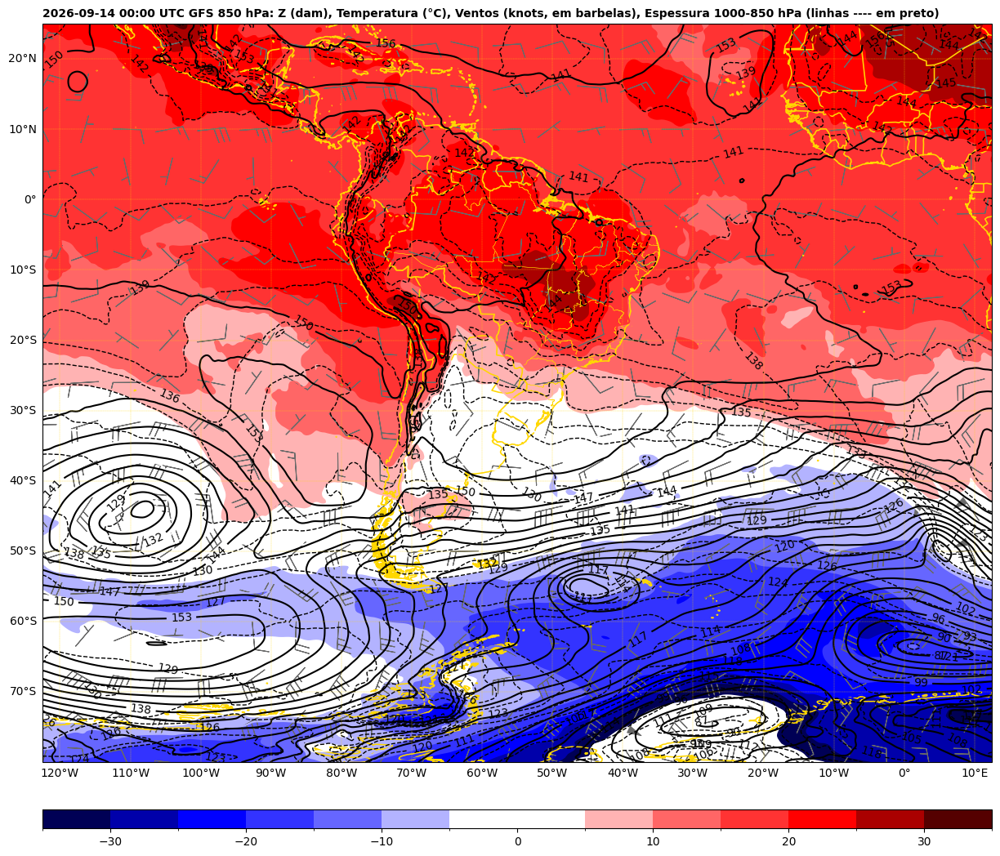

In [17]:
# @title #### <font color='#002883'> Altura gepotencial 850 hPa, Temperatura 850 hPa, Vento 850 hPa <font>
#%%capture

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl

# 1. Definição dos Limites (Bounds de -35 a +35 com passo de 5)
# O intervalo de -5 a 5 será um único bloco central.
bounds = [-35, -30, -25, -20, -15, -10, -5, 5, 10, 15, 20, 25, 30, 35]

# 2. Definição das Cores (13 cores para os 13 intervalos)
colors = [
    '#000055',  # -35 a -30 (Azul muito escuro/Marinho)
    '#0000AA',  # -30 a -25 (Azul escuro)
    '#0000FF',  # -25 a -20 (Azul puro)
    '#3333FF',  # -20 a -15 (Azul médio)
    '#6666FF',  # -15 a -10 (Azul claro)
    '#B3B3FF',  # -10 a -5  (Azul muito claro/Pastel)
    '#FFFFFF',  # -5  a  5  (BRANCO no centro)
    '#FFB3B3',  #  5  a 10  (Vermelho muito claro/Pastel)
    '#FF6666',  # 10  a 15  (Vermelho claro)
    '#FF3333',  # 15  a 20  (Vermelho médio)
    '#FF0000',  # 20  a 25  (Vermelho puro)
    '#AA0000',  # 25  a 30  (Vermelho escuro)
    '#550000'   # 30  a 35  (Vinho/Vermelho muito escuro)
]

# 3. Criando o Colormap e a Normalização por Fronteiras (BoundaryNorm)
custom_cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bounds, custom_cmap.N)

# ======================================================================
# CRIAÇÃO DA FIGURA
# ======================================================================

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# 850-hPa T
temp_850_C = temp_850.to(units.degC)
clevtemp = np.arange(-35,36,5)
cmap='nipy_spectral'
# Suavizando a variável
temp_850_C_plot = mpcalc.smooth_gaussian(temp_850_C, 8)
# Shaded
temp = ax.contourf(
    lons,
    lats,
    temp_850_C_plot,
    clevtemp,
    cmap=custom_cmap,
    norm=norm,
    transform=ccrs.PlateCarree()
)
# Contornos
tc = ax.contour(
    lons,
    lats,
    temp_850_C_plot,
    clevtemp,
    cmap=custom_cmap,
    norm=norm,
    transform=ccrs.PlateCarree()
)
# Colobar
plt.colorbar(
    temp,
    orientation='horizontal',
    pad=0.05,
    aspect=50,
    extendrect=True
)

# Plot thickness with multiple color
clevs = np.arange(0, 540, 1.5)
cs0 = ax.contour(lons, lats, thickness_1000_850_plot/10, clevs, colors='black',linewidths=1.0, linestyles='dashed', transform=ccrs.PlateCarree())
plt.clabel(cs0, fmt='%d')

# Plot Geopotential Heights
clevs_hght_850 = np.arange(0, 800, 3)
cs = ax.contour(
    lons,
    lats,
    hght_850_plot/10,
    clevs_hght_850,
    colors='black',
    transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
u_850_barb = u_850.to(units.knot)
v_850_barb = v_850.to(units.knot)
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_850_barb.shape[0],u_850_barb.shape[1]))

# All flags below the equator will be flipped
flip_flag[lats < 0] = 1

# Espaçamento das baerbelas
skip=24
bcolor='dimgrey'
# Suavizando os ventos
u_850_barb_plot = mpcalc.smooth_gaussian(u_850_barb, 8)
v_850_barb_plot = mpcalc.smooth_gaussian(v_850_barb, 8)
# plot da variável
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_850_barb_plot[::skip,::skip],
    v_850_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip]
)
# ===========================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='gold',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='gold', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='gold', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='gold',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC GFS 850 hPa: Z (dam), Temperatura (°C), Ventos (knots, em barbelas), Espessura 1000-850 hPa (linhas ---- em preto)',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/850_temp.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()

<font size=4 color='#002883'>**14. Altura geopotencial + Vorticidade + Advecção de temperatura - Nível 850 hPa**<font>

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


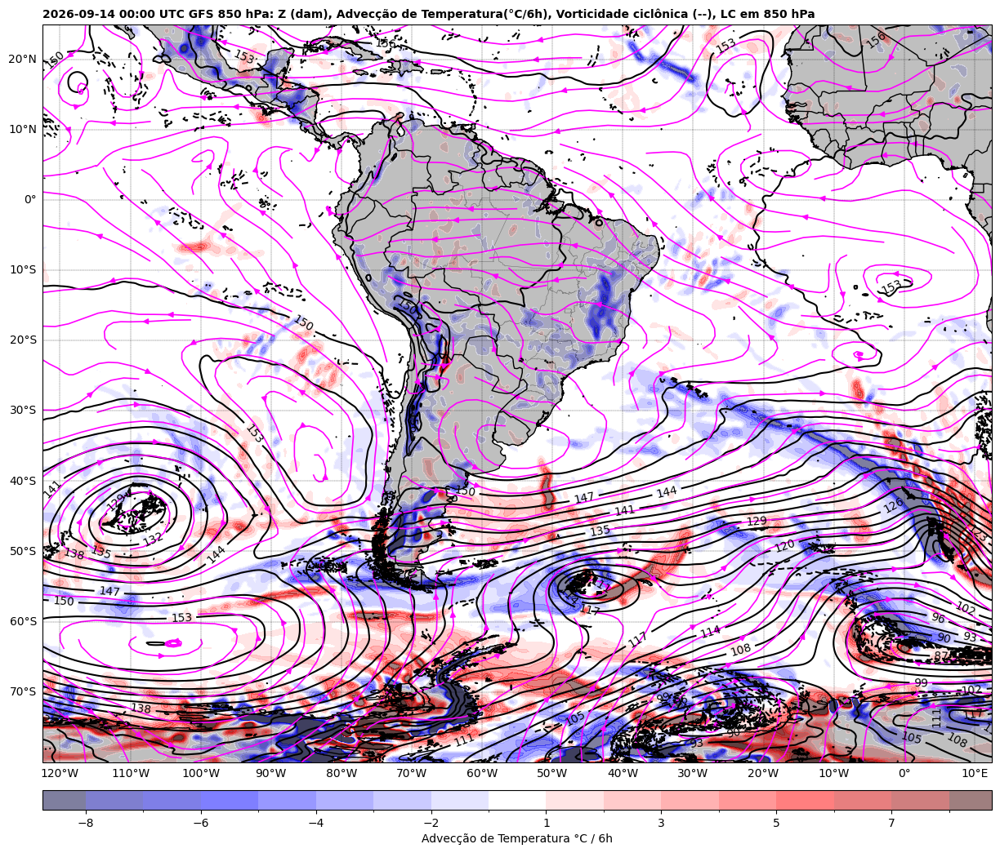

In [18]:
# @title #### <font color='#002883'> Altura gepotencial 850 hPa, vorticidade 850 hPa, Advecção de temperatura 850 hPa <font>
#%%capture
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl

# 1. Limites (bounds) de -10 a +10 com intervalo unitário e salto de -1 para 1
bounds = [-10, -9, -8, -7, -6, -5, -4, -3, -2, -1, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

# 2. Cores: 19 intervalos no total, com o branco no centro (índice 9)
colors = [
    '#000040', '#000070', '#0000A0', '#0000D0', '#0000FF',  # -10 a -5 (Azuis escuros ao puro)
    '#3333FF', '#6666FF', '#9999FF', '#CCCCFF',             # -5 a -1  (Azuis claros)
    '#FFFFFF',                                             # -1 a  1  (BRANCO)
    '#FFCCCC', '#FF9999', '#FF6666', '#FF3333',             #  1 a  5  (Vermelhos claros)
    '#FF0000', '#D00000', '#A00000', '#700000', '#400000'   #  5 a 10  (Vermelhos puros ao escuro)
]

# 3. Criando Colormap e Normalização
custom_cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bounds, custom_cmap.N)

# =======================================================================
# GERAR PLOT
# =======================================================================
# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# 850-hPa Colorfill of Temperature Advection
cint = np.arange(-8, 9,1)
# Suavizando a variável
adv_plot = mpcalc.smooth_gaussian(adv, 8)
# Plot da variável
cf = ax.contourf(
    lons,
    lats,
    6*adv_plot.to(units('delta_degC/hour')),
    cint[cint != 0],
    extend='both',
    cmap=custom_cmap, #'seismic',
    norm=norm,
    transform=ccrs.PlateCarree(),
    alpha=0.5,
    zorder=2
)
# Colorbar
cb = plt.colorbar(
    cf,
    orientation='horizontal',
    pad=0.03,
    aspect=50,
    extendrect=True
)
cb.set_label('Advecção de Temperatura °C / 6h')

# Plot Geopotential Heights
clevs_hght_850 = np.arange(0, 800, 3)
cs = ax.contour(
    lons,
    lats,
    hght_850_plot/10,
    clevs_hght_850,
    colors='black',
    transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# 850-hPa vort
clevzeta = np.arange(-50, 0, 2)
# Suavizando a variável
zeta_850_plot = mpcalc.smooth_gaussian(zeta_850, 4)
# Plot da variável
zeta = ax.contour(
    lons,
    lats,
    zeta_850_plot*10**5,
    clevzeta,
    colors='black',
    transform=ccrs.PlateCarree(),
    zorder=3
)
#plt.colorbar(zeta, orientation='horizontal', pad=0.05, aspect=50, extendrect=True)

# Suavizando os ventos
u_850_plot = mpcalc.smooth_gaussian(u_850, 8)
v_850_plot = mpcalc.smooth_gaussian(v_850, 8)
# Linhas de corrente
ax.streamplot(
    lons,
    lats,
    u_850_plot,
    v_850_plot,
    density=[1.5, 1.5],
    linewidth=1.2,
    color='magenta'
)

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.add_feature(cfeature.LAND, facecolor='gray', zorder=1)
ax.coastlines(resolution='10m', color='black', linewidth=1, zorder=3)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1, zorder=3)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True,
    zorder=4
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS 850 hPa: Z (dam), Advecção de Temperatura(°C/6h), Vorticidade ciclônica (--), LC em 850 hPa',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/850_advT_Vort.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()

<font size=4 color='#002883'>**15. Imagem de satélite + Altura geopotencial e vorticidade - Nível: 500 hPa**<font>

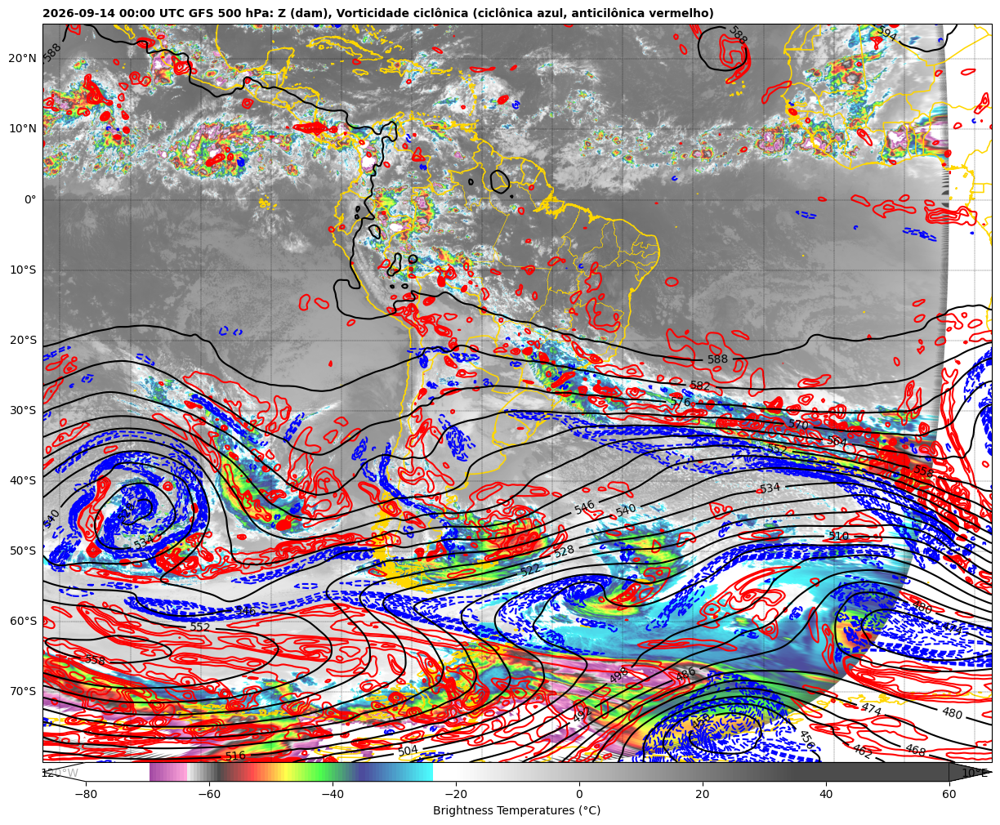

In [19]:
# @title #### <font color='#002883'> Imagem de satélite, altura geopotencial e vorticidade em 500 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# Define the color scale based on the channel
# Converts a CPT file to be used in Python
cpt = loadCPT('IR4AVHRR6.cpt')
colormap = cm.colors.LinearSegmentedColormap('cpt', cpt)

# Plot the image
img1 = ax.imshow(
    data,
    origin='upper',
    vmin=-80,
    vmax=60,
    extent=img_extent,
    cmap=colormap,
    alpha=0.7
)
# Add a colorbar
plt.colorbar(
    img1,
    label='Brightness Temperatures (°C)',
    extend='both',
    orientation='horizontal',
    pad=0,
    aspect=50
)

# 500-hPa vort
clevzeta = np.arange(-50, -4, 2)
# Suavizando a variável
zeta_500_plot = mpcalc.smooth_gaussian(zeta_500, 8)
# Plot da variável
zeta = ax.contour(
    lons,
    lats,
    zeta_500_plot*10**5,
    clevzeta,
    colors='blue',
    transform=ccrs.PlateCarree()
)

#plt.colorbar(zeta, orientation='horizontal', pad=0.05, aspect=50, extendrect=True)
clevzeta = np.arange(4, 50, 2)
zeta = ax.contour(
    lons,
    lats,
    zeta_500_plot*10**5,
    clevzeta,
    colors='red',
    transform=ccrs.PlateCarree()
)

# Plot Geopotential Heights
clevs_hght_500 = np.arange(0, 800, 6)
# Suavizando a variável
hght_500_plot = mpcalc.smooth_gaussian(hght_500, 8)
# Plot da variável
cs = ax.contour(
    lons,
    lats,
    hght_500_plot/10,
    clevs_hght_500,
    colors='black',
    transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='gold',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='gold', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='gold', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS 500 hPa: Z (dam), Vorticidade ciclônica (ciclônica azul, anticilônica vermelho)',
          fontweight='bold',
          fontsize=10,
          loc='left'
)
#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/500_Sat_Vort.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**16. Altura geopotencial + vorticidade + vento (barbelas, knots) + omega (negativo) - Nível = 500 hPa**<font>

/usr/local/lib/python3.13/dist-packages/cartopy/mpl/geoaxes.py:1585: UserWarning: The following kwargs were not used by contour: 'linewidth'
  result = super().contour(*args, **kwargs)


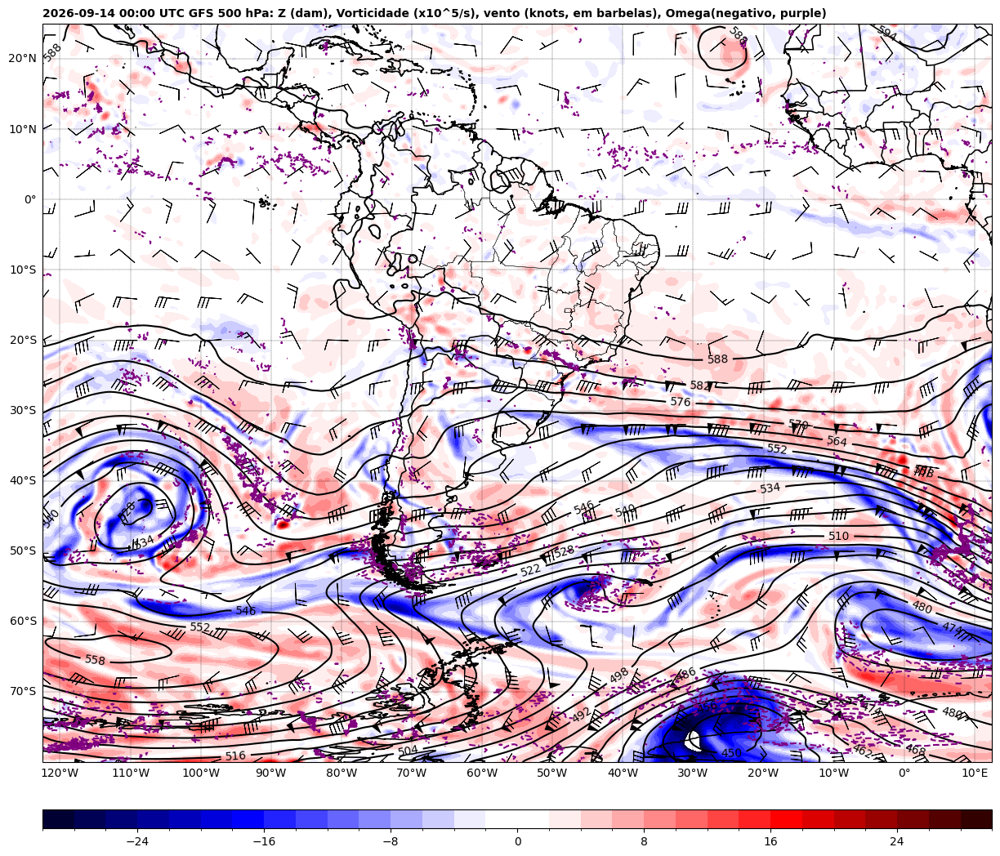

In [21]:
# @title #### <font color='#002883'> Altura geopotencial, vorticidadem vento e omega (negativo) em 500 hPa <font>
#%%capture

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl

# 1. Limites (bounds) de -30 a +30 com passo de 2, pulando de -2 direto para 2
bounds = [
    -30, -28, -26, -24, -22, -20, -18, -16, -14, -12, -10, -8, -6, -4, -2,
    2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30
]

# 2. Cores (29 intervalos no total, com o branco no centro)
colors = [
    '#000033', '#000055', '#000077', '#000099', '#0000BB', '#0000DD', '#0000FF',  # Azuis muito escuros ao puro
    '#2222FF', '#4444FF', '#6666FF', '#8888FF', '#AAAAFF', '#CCCCFF', '#EEEEFF',  # Azuis claros
    '#FFFFFF',                                                                 # -2 a 2 (BRANCO)
    '#FFEEEE', '#FFCCCC', '#FFAAAA', '#FF8888', '#FF6666', '#FF4444', '#FF2222',  # Vermelhos claros
    '#FF0000', '#DD0000', '#BB0000', '#990000', '#770000', '#550000', '#330000'   # Vermelhos puros ao escuro
]

# 3. Criando Colormap e Normalização
custom_cmap = mcolors.ListedColormap(colors)
norm = mcolors.BoundaryNorm(bounds, custom_cmap.N)

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# 500-hPa vort
clevzeta = np.arange(-30, 31, 2)
zeta = ax.contourf(
    lons,
    lats,
    zeta_500_plot*10**5,
    clevzeta,
    cmap=custom_cmap, #'seismic',
    norm=norm,
    transform=ccrs.PlateCarree()
)
plt.colorbar(
    zeta,
    orientation='horizontal',
    pad=0.05,
    aspect=50,
    extendrect=True
)

# Plot Geopotential Heights
clevs_hght_500 = np.arange(0, 800, 6)
cs = ax.contour(
    lons,
    lats,
    hght_500_plot/10,
    clevs_hght_500,
    colors='black',
    transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# Plot Omega
clevs_w_500 = np.arange(-50,0,0.3)
# Suavizando a variável
w_500_plot = mpcalc.smooth_gaussian(w_500, 2)
# Plot da variável
csw = ax.contour(
    lons,
    lats,
    w_500_plot,
    clevs_w_500,
    colors='purple',
    linewidth=0.25,
    transform=ccrs.PlateCarree()
)
#plt.clabel(cs, fmt='%d')

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
u_500_barb = u_500.to(units.knot)
v_500_barb = v_500.to(units.knot)
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_500_barb.shape[0],u_500_barb.shape[1]))

# All flags below the equator will be flipped
flip_flag[lats < 0] = 1

# Espaçamento das baerbelas
skip=24
bcolor='black'
# Suavizando os ventos
u_500_barb_plot = mpcalc.smooth_gaussian(u_500_barb, 8)
v_500_barb_plot = mpcalc.smooth_gaussian(v_500_barb, 8)
# plot da variável
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_500_barb_plot[::skip,::skip], v_500_barb_plot[::skip,::skip],
    length = 6.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.7,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip]
)

# ===========================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='black', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS 500 hPa: Z (dam), Vorticidade (x10^5/s), vento (knots, em barbelas), Omega(negativo, purple)',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/500_Vort.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**17. Imagem de satélite + Altura geopotencial + Jatos - Nível: 250 hPa**<font>

/usr/local/lib/python3.13/dist-packages/cartopy/mpl/geoaxes.py:1585: UserWarning: The following kwargs were not used by contour: 'linestyle'
  result = super().contour(*args, **kwargs)


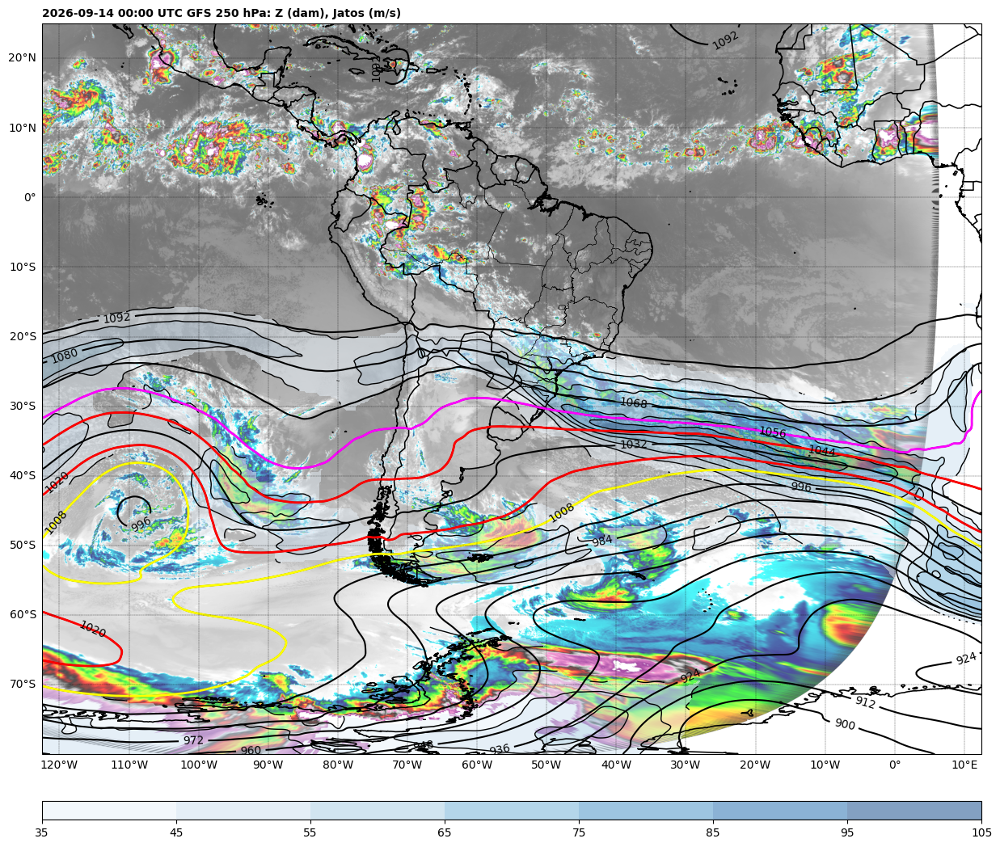

In [26]:
# @title #### <font color='#002883'> Imagem de satélite, Altura geopotencial, jatos em 250 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# Define the color scale based on the channel
# Converts a CPT file to be used in Python
cpt = loadCPT('IR4AVHRR6.cpt')
colormap = cm.colors.LinearSegmentedColormap('cpt', cpt)

# Plot the image
img1 = ax.imshow(
    data,
    origin='upper',
    vmin=-80,
    vmax=60,
    extent=img_extent,
    cmap=colormap,
    alpha=0.7
)
# Add a colorbar
#plt.colorbar(img1, label='Brightness Temperatures (°C)', extend='both', orientation='horizontal', pad=0, aspect = 50)

# Plot jets
# 250-hPa jet
clevjet = np.arange(35,106,10)
# Suavizando o jato
speed_jet_plot = mpcalc.smooth_gaussian(speed_jet, 8)
# plot da variável
jet250 = ax.contourf(
    lons,
    lats,
    speed_jet_plot,
    clevjet,
    cmap='Blues',
    alpha=0.5,
    transform=ccrs.PlateCarree()
)
# Contornos do jato
cjet = ax.contour(
    lons,
    lats,
    speed_jet_plot,
    clevjet,
    colors='black',
    linestyle='dotted',
    linewidths=1,
    transform=ccrs.PlateCarree()
)
# Colorbar
plt.colorbar(
    jet250,
    orientation='horizontal',
    pad=0.05,
    aspect=50,
    extendrect=True
)

# Plot Geopotential Heights
clevs_hght_250 = np.arange(0, 2000, 12)
# Suavizando a variável
hght_250_plot = mpcalc.smooth_gaussian(hght_250, 8)
# plot da variável
cs = ax.contour(lons,
                lats,
                hght_250_plot/10,
                clevs_hght_250,
                colors='black',
                transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# =============================================================================================================================================
# IDENTIFICANDO OS JATOS
# =============================================================================================================================================

# Plot Z - Jato Subtropical
clevzjet_subtropical = np.arange(10560., 10561., 1)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_subtropical, colors='magenta', linewidths=2.0, linestyles='-',transform=ccrs.PlateCarree())

# Plot Z - Ramo norte do Jato Polar
clevzjet_polar_norte = np.arange(10200., 10500., 240)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_polar_norte, colors='red', linewidths=2.0,linestyles='-',transform=ccrs.PlateCarree())

# Plot Z - Ramo Sul do Jato Polar
clevzjet_polar_sul = np.arange(10080., 10081., 1)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_polar_sul, colors='yellow', linewidths=2.0,linestyles='-',transform=ccrs.PlateCarree())

# =============================================================================================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='black', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS 250 hPa: Z (dam), Jatos (m/s)',
          fontweight='bold',
          fontsize=10,
          loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/250_Sat_Jatos.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**18. Imagem de satélite + LC Nível: 250 hPa**<font>

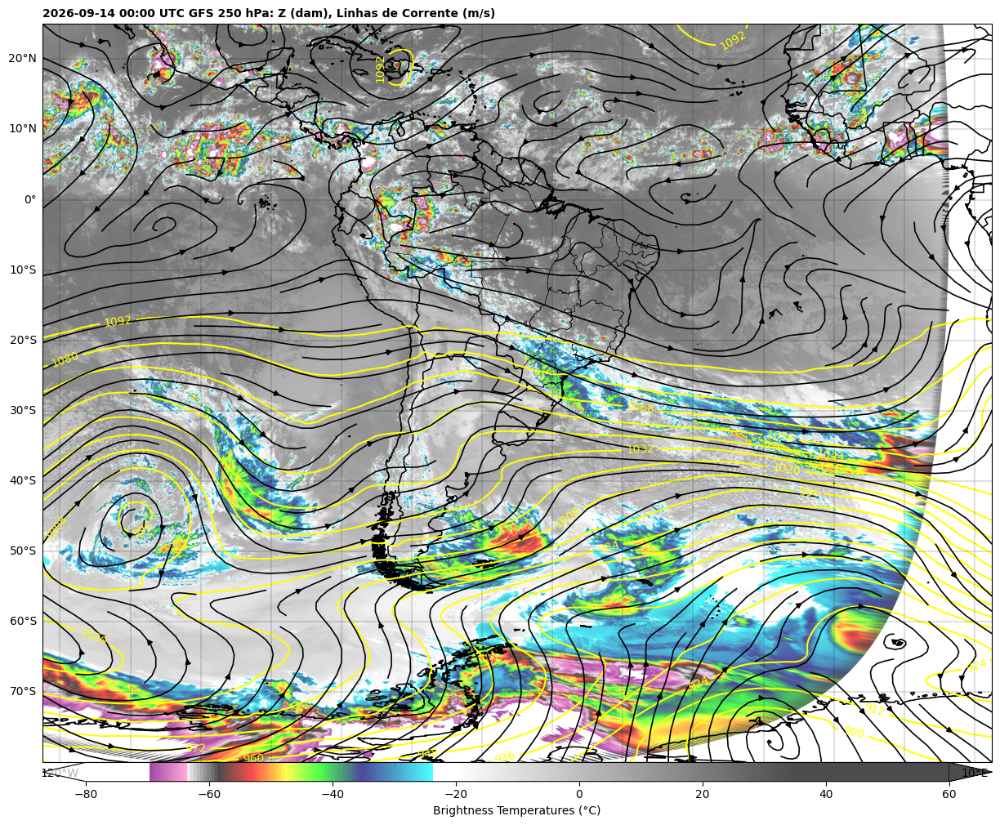

In [27]:
# @title #### <font color='#002883'> Imagem de satélite, Linhas de Corrente em 250 hPa <font>
#%%capture

# Plotando 250: Z e jatos
# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Define the image extent
img_extent = [extent[0], extent[2], extent[1], extent[3]]

# Define the color scale based on the channel
# Converts a CPT file to be used in Python
cpt = loadCPT('IR4AVHRR6.cpt')
colormap = cm.colors.LinearSegmentedColormap('cpt', cpt)

# Plot the image
img1 = ax.imshow(
    data,
    origin='upper',
    vmin=-80,
    vmax=60,
    extent=img_extent,
    cmap=colormap,
    alpha=0.7
)
# Add a colorbar
plt.colorbar(
    img1,
    label='Brightness Temperatures (°C)',
    extend='both',
    orientation='horizontal',
    pad=0,
    aspect = 50
)

# Plot Geopotential Heights
clevs_hght_250 = np.arange(0, 2000, 12)
cs = ax.contour(
    lons,
    lats,
    hght_250_plot/10,
    clevs_hght_250,
    colors='yellow',
    transform=ccrs.PlateCarree()
)
plt.clabel(cs, fmt='%d')

# Suavizando os ventos
u_250_plot = mpcalc.smooth_gaussian(u_250, 8)
v_250_plot = mpcalc.smooth_gaussian(v_250, 8)
# Linhas de corrente
ax.streamplot(
    lons,
    lats,
    u_250_plot,
    v_250_plot,
    density=[1.5, 1.5],
    linewidth=1.2,
    color='black'
)

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.coastlines(resolution='10m', color='black', linewidth=1.15)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS 250 hPa: Z (dam), Linhas de Corrente (m/s)',
          fontweight='bold',
          fontsize=10, loc='left'
)

#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/250_Sat_LC.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**19. PRNMM + Espessura 1000-500 hPa + Jet 250 hPa e vento em barbelas (knots) em 1000 hPa**<font>

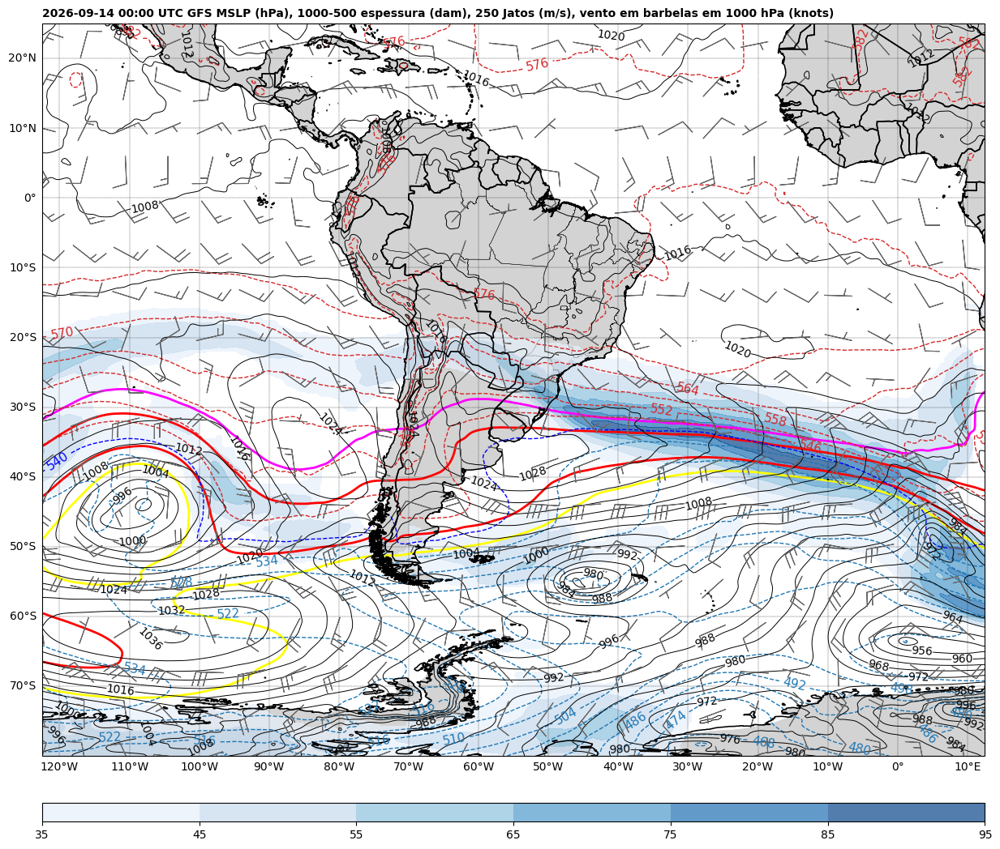

In [28]:
# @title #### <font color='#002883'> PRNMM + Espessura 1000-500 hPa + Jet 250 hPa e vento em barbelas em 1000 hPa <font>
#%%capture

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# =============================================================================================================================================
# IDENTIFICANDO OS JATOS
# =============================================================================================================================================
# 250-hPa jet
clevjet = np.arange(35,96,10)
jet250 = ax.contourf(
    lons,
    lats,
    speed_jet_plot,
    clevjet,
    cmap='Blues',
    zorder=2,
    alpha=0.7,
    transform=ccrs.PlateCarree()
)

# Colorbar
plt.colorbar(
    jet250,
    orientation='horizontal',
    pad=0.05,
    aspect=50,
    extendrect=True)

# Plot Z - Jato Subtropical
clevzjet_subtropical = np.arange(10560., 10561., 1)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_subtropical, colors='magenta', linewidths=2.0, linestyles='-',transform=ccrs.PlateCarree())

# Plot Z - Ramo norte do Jato Polar
clevzjet_polar_norte = np.arange(10200., 10500., 240)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_polar_norte, colors='red', linewidths=2.0,linestyles='-',transform=ccrs.PlateCarree())

# Plot Z - Ramo Sul do Jato Polar
clevzjet_polar_sul = np.arange(10080., 10081., 1)
cs = ax.contour(lons, lats, hght_250_plot, clevzjet_polar_sul, colors='yellow', linewidths=2.0,linestyles='-',transform=ccrs.PlateCarree())
# =============================================================================================================================================

# Plot thickness with multiple colors
clevs = (np.arange(0, 540, 6),
         np.array([540]),
         np.arange(546, 700, 6))
colors = ('tab:blue', 'b', 'tab:red')
kw_clabels = {'fontsize': 11, 'inline': True, 'inline_spacing': 5, 'fmt': '%i',
              'rightside_up': True, 'use_clabeltext': True}
for clevthick, color in zip(clevs, colors):
    img2 = ax.contour(
        lons,
        lats,
        thickness_1000_500_plot/10,
        levels=clevthick,
        colors=color,
        linewidths=1.0,
        linestyles='dashed',
        transform=ccrs.PlateCarree()
    )
    plt.clabel(img2, **kw_clabels)

# Define de contour interval
data_min = 900
data_max = 1050
interval = 4
levels = np.arange(data_min,data_max,interval)

# Plot the contours
img3 = ax.contour(
    lons,
    lats,
    mslp_plot,
    colors='black',
    linewidths=0.7,
    levels=levels
)
# Etiquetas
ax.clabel(
    img3,
    inline=1,
    inline_spacing=0,
    fontsize='10',
    fmt = '%1.0f',
    colors= 'black'
)

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_1000_barb.shape[0],u_1000_barb.shape[1]))
# All flags below the equator will be flipped
flip_flag[lats < 0] = 1
# Espaçamento das barbelas
skip=24
bcolor='dimgrey'
# Suavizando os ventos em barbelas
u_1000_barb_plot = mpcalc.smooth_gaussian(u_1000_barb, 8)
v_1000_barb_plot = mpcalc.smooth_gaussian(v_1000_barb, 8)
# Plot do vento em barbelas
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_1000_barb_plot[::skip,::skip],
    v_1000_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip],
    zorder=2
)

# ======================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=1)
ax.coastlines(resolution='10m', color='black', linewidth=1.15, zorder=3)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.15, zorder=3)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    zorder=4,
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS MSLP (hPa), 1000-500 espessura (dam), 250 Jatos (m/s), vento em barbelas em 1000 hPa (knots)',
          fontweight='bold',
          fontsize=10, loc='left'
)
#plt.title('Reg.: ' + str(extent) , fontsize=10, loc='right')
#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/MSLP_Thick_Jatos.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()


<font size=4 color='#002883'>**20. MSLP + Precipitation rate [mm/6h] + Temperatura 850 (positivo vermelho, negativo azul) + Vento 1000 hPa (knots, barbelas)**<font>

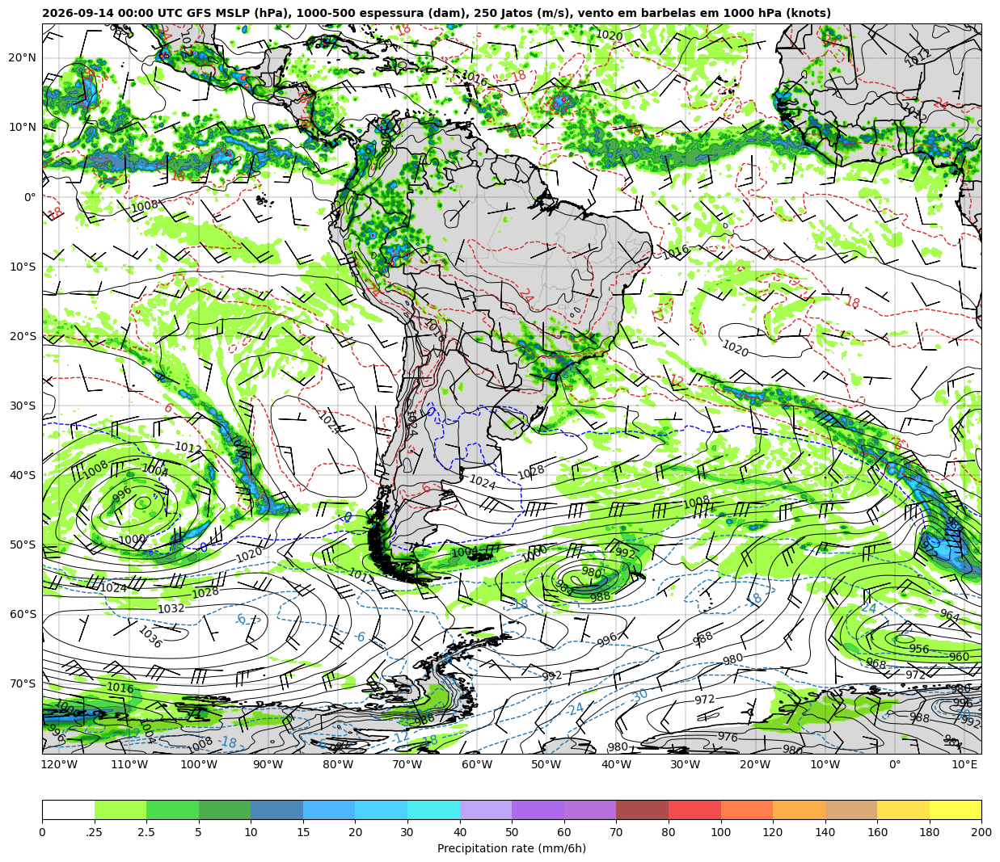

In [29]:
# @title #### <font color='#002883'> MSLP + Precipitation rate [mm/6h] + Temperatura 850 + Vento 1000 hPa <font>
#%%capture

# =======================================================================================================
# CRIANDO A BARRA DE CORES BASEADO NO SITE:
# Link: https://www.atmos.albany.edu/student/abentley/realtime.html
# =======================================================================================================
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import cartopy.feature as cfeature

# 1. Definição das Cores Exatas da sua Imagem (Lista de Hexadecimais)
# Começa no branco (0-0.25) e termina no creme claro (>200)
hex_colors = [
    '#FFFFFF',  # 0.0 - 0.25  (Branco)
    '#7FFF00',  # 0.25 - 2.5  (Verde Limão claro)
    '#00CD00',  # 2.5 - 5.0   (Verde Vibrante)
    '#008B00',  # 5.0 - 10.0  (Verde Escuro)
    '#005596',  # 10.0 - 15.0 (Azul Marinho)
    '#0099FF',  # 15.0 - 20.0 (Azul Piscina)
    '#00BFFF',  # 20.0 - 30.0 (Ciano)
    '#00E5EE',  # 30.0 - 40.0 (Ciano Claro)
    '#A47FF3',  # 40.0 - 50.0 (Lilás)
    '#8A2BE2',  # 50.0 - 60.0 (Violeta Profundo)
    '#9932CC',  # 60.0 - 70.0 (Roxo "Dark Orchid")
    '#8B0000',  # 70.0 - 80.0 (Vermelho Escuro/Vinho)
    '#EE0000',  # 80.0 - 100.0(Vermelho Puro)
    '#FF4500',  # 100 - 120   (Laranja Avermelhado)
    '#FF8C00',  # 120 - 140   (Laranja "Dark Orange")
    '#CD853F',  # 140 - 160   (Laranja Queimado/"Peru")
    '#FFD700',  # 160 - 180   (Ouro/Amarelo Escuro)
    '#FFFF00',  # 180 - 200   (Amarelo Puro)
    '#FFFACD'   # > 200        (Creme/"Lemon Chiffon")
]

# 2. Definição dos Limites (Níveis)
# Baseado na sua lista 'clevpreciprate'
bounds = [0, 0.25, 2.5, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 100, 120, 140, 160, 180, 200, 250]
# Nota: Adicionei '250' apenas para definir o último intervalo colorido.

# 3. Criando o Objeto Colormap e Normalização
# Cria um colormap "listado" (discreto) com as cores definidas
custom_cmap = mcolors.ListedColormap(hex_colors)
# Cria uma normalização "por fronteiras", essencial para dados meteorológicos/discretos
norm = mcolors.BoundaryNorm(bounds, custom_cmap.N)

# Choose the plot size (width x height, in inches)
plt.figure(figsize=(15,15))

# Use the Geostationary projection in cartopy
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([extent[0], extent[2], extent[1], extent[3]], ccrs.PlateCarree())

# Plotando Precipitation rate
clevpreciprate = [0, 0.25, 2.5, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 100, 120, 140, 160, 180, 200]
# Criando o vetor com os valores de precipitação
precip_rate_values = precip_rate.values  # <--- .values é indispensável aqui!
# Se o dado estiver em kg/m²/s e você quiser exibir em mm/6h:
precip_rate_mm6h = precip_rate_values * 3600 * 6
# Gerando o plot
cs2 = ax.contourf(
    lons,
    lats,
    precip_rate_mm6h,
    clevpreciprate,
    cmap =custom_cmap,
    norm=norm,
    alpha=0.7,
    zorder=2
)

# Gerando a barra do Precipitation rate (mm/6h)
cb = plt.colorbar(
    cs2,
    label='Precipitation rate (mm/6h)',
    orientation="horizontal",
    ticks=clevpreciprate,
    pad=0.05,
    aspect=50
)

# Ajuste os rótulos (opcional, para replicar o estilo da imagem)
ticks = [str(x) if x != 0.25 else '.25' for x in clevpreciprate]
cb.ax.set_xticklabels(ticks)

# Plot thickness with multiple colors
clevs = (np.arange(-30, 0, 6),
         np.array([0]),
         np.arange(6, 31, 6))
colors = ('tab:blue', 'b', 'tab:red')
kw_clabels = {'fontsize': 11, 'inline': True, 'inline_spacing': 5, 'fmt': '%i',
              'rightside_up': True, 'use_clabeltext': True}
for clevthick, color in zip(clevs, colors):
    img2 = ax.contour(
        lons,
        lats,
        temp_850_C_plot,
        levels=clevthick,
        colors=color,
        linewidths=1.0,
        linestyles='dashed',
        transform=ccrs.PlateCarree()
    )
    plt.clabel(img2, **kw_clabels)

# Define de contour interval
data_min = 900
data_max = 1050
interval = 4
levels = np.arange(data_min,data_max,interval)

# Plot the contours
img3 = ax.contour(
    lons,
    lats,
    mslp_plot,
    colors='black',
    linewidths=0.7,
    levels=levels
)
# Etiquetas
ax.clabel(
    img3,
    inline=1,
    inline_spacing=0,
    fontsize='10',
    fmt = '%1.0f',
    colors= 'black'
)

# ==========================================================================
# VENTO EM KNOTS PARA O FORMATO DE BARBAS
# ==========================================================================
# Create a flag to determine which barbs are flipped
flip_flag = np.zeros((u_1000_barb.shape[0],u_1000_barb.shape[1]))
# All flags below the equator will be flipped
flip_flag[lats < 0] = 1
# Espaçamento das barbelas
skip=24
bcolor='black'
# Suavizando os ventos em barbelas
u_1000_barb_plot = mpcalc.smooth_gaussian(u_1000_barb, 8)
v_1000_barb_plot = mpcalc.smooth_gaussian(v_1000_barb, 8)
# Plot do vento em barbelas
img4 = ax.barbs(
    lons[::skip,::skip],
    lats[::skip,::skip],
    u_1000_barb_plot[::skip,::skip],
    v_1000_barb_plot[::skip,::skip],
    length = 7.0,
    sizes = dict(emptybarb=0.0, spacing=0.2, height=0.5),
    linewidth=0.8,
    pivot='middle',
    barbcolor=bcolor,
    flip_barb = flip_flag[::skip,::skip],
    zorder=2
)

# ======================================================================

# Add a shapefile
# https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/malhas_municipais/municipio_2019/Brasil/BR/br_unidades_da_federacao.zip
shapefile = list(shpreader.Reader('BR_UF_2019.shp').geometries())
ax.add_geometries(shapefile, ccrs.PlateCarree(), edgecolor='black',facecolor='none', linewidth=0.3)

# Add coastlines, borders and gridlines
ax.add_feature(cfeature.LAND, facecolor='gray', zorder=1)
ax.coastlines(resolution='10m', color='black', linewidth=1.15, zorder=3)
ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.15, zorder=3)
ax.add_feature(cartopy.feature.BORDERS, edgecolor='black', linewidth=1.15)
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    color='black',
    alpha=1.0,
    linestyle='--',
    linewidth=0.25,
    xlocs=np.arange(-180, 180, 10),
    ylocs=np.arange(-90, 90, 10),
    zorder=4,
    draw_labels=True
)
gl.top_labels = False
gl.right_labels = False

# Extract date
date = (datetime.strptime(dtime, '%Y-%m-%dT%H:%M:%S.%fZ'))

# Add a title
plt.title(date.strftime('%Y-%m-%d %H:%M') + ' UTC' + ' GFS MSLP (hPa), 1000-500 espessura (dam), 250 Jatos (m/s), vento em barbelas em 1000 hPa (knots)',
          fontweight='bold',
          fontsize=10, loc='left'
)
#plt.title('Reg.: ' + str(extent) , fontsize=10, loc='right')
#-----------------------------------------------------------------------------------------------------------
# Save the image
plt.savefig(f'{output}/MSLP_Thick_Jatos.png', bbox_inches='tight', pad_inches=0, dpi=300)

# Show the image
plt.show()